In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/bgg_data_named_na_years_removed.csv')

In [3]:
# Create a subset of df where category contains 'Card Game'
# ---- Change this to investigate a different category --------------------------
CATEGORY = 'Card Game'
# --------------------------------------------------------------------------------

# The category column is a comma-separated list, so match whole entries
cat_df = df[df['category'].fillna('').str.split(', ').apply(lambda cats: CATEGORY in cats)].copy()

# Display the size of the subset and the first few rows
print(f"Number of games in the 'Card Game' subset: {len(cat_df)}")
cat_df[['name', 'year', 'category', 'avg_rating']]

Number of games in the 'Card Game' subset: 27266


,name,year,category,avg_rating
1,Dragonmaster,1981,"Card Game, Fantasy",6.65823
10,Bohnanza,1997,"Card Game, Farming, Negotiation",7.04409
27,Illuminati,1987,"Card Game, Humor, Negotiation, Political, Scie...",6.47505
41,David & Goliath,1997,Card Game,6.46956
46,Mamma Mia!,1998,"Card Game, Memory",6.46953
...,...,...,...,...
104200,Clash of Corgis,2023,"Animals, Card Game",NaN
104201,De Quem É O Reino?,2021,"Animals, Bluffing, Card Game",NaN
104203,A game about auctioning cubes after winning an...,2023,Card Game,8.00000
104211,Balloons!,2023,"Card Game, Children's Game, Educational, Party...",NaN


In [4]:
# Sort by average rating, then by number of votes (highest first)
sorted_df = cat_df.sort_values(by=['avg_rating', 'num_votes'], ascending=False)

In [5]:
from ipywidgets import interact, IntSlider, Layout
from IPython.display import display

cutoff_min_votes = 1000

# Only keep games with enough votes, so a handful of early votes can't produce a perfect 10.0
popular_df = sorted_df[sorted_df['num_votes'] >= cutoff_min_votes]

def show_top_games(cutoff_year):
    # 10 best entries from cutoff_year onwards
    group_1 = popular_df[popular_df['year'] >= cutoff_year].head(10)
    print(f"--- Top 10 entries from {cutoff_year} onwards ---")
    display(group_1[['name', 'year', 'category', 'avg_rating']])

    # 10 best entries before cutoff_year
    group_2 = popular_df[popular_df['year'] < cutoff_year].head(10)
    print(f"\n--- Top 10 entries before {cutoff_year} ---")
    display(group_2[['name', 'year', 'category', 'avg_rating']])

# Drag the slider (or click it and use the arrow keys) to move the cutoff year
interact(
    show_top_games,
    cutoff_year=IntSlider(
        min=1950,
        max=int(popular_df['year'].max()),
        step=1,
        value=2000,
        description='Cutoff year',
        continuous_update=False,   # update when you release the slider, not on every pixel
        style={'description_width': 'initial'},
        layout=Layout(width='600px'),
    ),
);

interactive(children=(IntSlider(value=2000, continuous_update=False, description='Cutoff year', layout=Layout(…

In [6]:
import io
import ipywidgets as widgets
from ipywidgets import IntSlider, Layout
from IPython.display import display
from matplotlib.figure import Figure       # no pyplot, so nothing can auto-display a figure
from matplotlib.patches import Patch

# Colours: blue = before the cutoff, orange = from the cutoff onwards
COLOR_BEFORE = '#2a78d6'
COLOR_AFTER  = '#eb6834'
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2de'
N_SLOTS = 10          # rows per side
X_MAX = 11            # rating axis runs 0-10; the extra room holds the value labels


def short(text, n=34):
    return text if len(text) <= n else text[:n - 1] + '…'


def draw_side(ax, rows, color, mirrored, empty_msg):
    """One half of the butterfly chart. mirrored=True grows bars to the left."""
    ax.set_facecolor(SURFACE)
    ax.set_ylim(N_SLOTS - 0.5, -0.5)                      # rank 1 at the top, fixed height
    ax.set_xlim((X_MAX, 0) if mirrored else (0, X_MAX))
    ax.set_xticks(range(0, 11, 2))
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis='both', length=0, labelsize=9, labelcolor=INK_2)
    if not mirrored:
        ax.yaxis.tick_right()

    if rows.empty:
        ax.set_yticks([])
        ax.text(0.5, 0.5, empty_msg, transform=ax.transAxes, ha='center', va='center',
                color=INK_2, fontsize=10)
        return

    ypos = list(range(len(rows)))
    ax.barh(ypos, rows['avg_rating'], height=0.62, color=color)
    ax.set_yticks(ypos)
    ax.set_yticklabels(
        [f"{short(n)} ({int(y)})" for n, y in zip(rows['name'], rows['year'])],
        fontsize=9.5, color=INK)
    for y, rating in zip(ypos, rows['avg_rating']):
        ax.text(rating + 0.12, y, f"{rating:.2f}", va='center',
                ha='right' if mirrored else 'left', fontsize=9, color=INK)


def render_chart(cutoff_year, min_votes):
    """Build the chart and return it as PNG bytes."""
    pool = sorted_df[sorted_df['num_votes'] >= min_votes]
    before = pool[pool['year'] < cutoff_year].head(N_SLOTS)
    after = pool[pool['year'] >= cutoff_year].head(N_SLOTS)

    fig = Figure(figsize=(14, 6.4), facecolor=SURFACE)
    ax_l, ax_r = fig.subplots(1, 2)
    fig.subplots_adjust(left=0.21, right=0.79, wspace=0.03, top=0.80, bottom=0.12)
    msg = f"No games in this period with at least {min_votes:,} votes"
    draw_side(ax_l, before, COLOR_BEFORE, mirrored=True, empty_msg=msg)
    draw_side(ax_r, after, COLOR_AFTER, mirrored=False, empty_msg=msg)

    fig.suptitle(f"Top card games by average rating, before vs. from {cutoff_year} onwards",
                 x=0.5, y=0.96, fontsize=14, fontweight='bold', color=INK)
    fig.text(0.5, 0.905, f"Games with at least {min_votes:,} votes · top {N_SLOTS} on each side",
             ha='center', fontsize=10, color=INK_2)
    fig.legend(handles=[Patch(color=COLOR_BEFORE, label=f"Before {cutoff_year}"),
                        Patch(color=COLOR_AFTER, label=f"{cutoff_year} onwards")],
               loc='upper center', bbox_to_anchor=(0.5, 0.875), ncol=2, frameon=False,
               fontsize=10, labelcolor=INK)
    fig.text(0.5, 0.04, "Average rating (0–10)", ha='center', fontsize=10, color=INK_2)

    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=100, facecolor=SURFACE)
    return buf.getvalue()


# The chart lives in ONE image widget. Moving a slider only swaps that image's
# contents, so a second chart can never be added to the page.
chart = widgets.Image(format='png', layout=Layout(width='100%', max_width='1400px'))

year_slider = IntSlider(
    min=1950, max=2023, step=1, value=2000, description='Cutoff year',
    continuous_update=False, style={'description_width': 'initial'},
    layout=Layout(width='600px'))
votes_slider = IntSlider(
    min=50, max=5000, step=50, value=1000, description='Min. votes',
    continuous_update=False, style={'description_width': 'initial'},
    layout=Layout(width='600px'))


def update(change=None):
    chart.value = render_chart(year_slider.value, votes_slider.value)


year_slider.observe(update, names='value')
votes_slider.observe(update, names='value')

display(widgets.VBox([year_slider, votes_slider, chart]))
update()   # draw the first chart

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Shared styling for the charts below
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#b9b8b2'
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2de'


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=9, labelcolor=INK_2)


def short(text, n=32):
    return text if len(text) <= n else text[:n - 1] + '…'


def label_points(ax, rows, x, y):
    """Label a handful of points, staggering the offsets so labels don't pile up."""
    offsets = [(14, 10), (-14, 10), (14, -12), (-14, -12)]
    for i, (_, r) in enumerate(rows.iterrows()):
        dx, dy = offsets[i % 4]
        ax.annotate(f"{short(r['name'])} ({int(r['year'])})", (r[x], r[y]),
                    xytext=(dx, dy), textcoords='offset points',
                    ha='left' if dx > 0 else 'right', fontsize=9, color=INK,
                    arrowprops=dict(arrowstyle='-', color=INK_2, linewidth=0.6))



def label_column(ax, rows, x, y, x_text, y_top, dy):
    """Label points in a tidy column (data coordinates), joined to their points by thin lines."""
    for i, (_, r) in enumerate(rows.iterrows()):
        ax.annotate(f"{short(r['name'])} ({int(r['year'])})", (r[x], r[y]),
                    xytext=(x_text, y_top - i * dy), textcoords='data',
                    ha='left', va='center', fontsize=9, color=INK,
                    bbox=dict(boxstyle='round,pad=0.15', fc=SURFACE, ec='none', alpha=0.9),
                    arrowprops=dict(arrowstyle='-', color=INK_2, linewidth=0.6, shrinkA=0, shrinkB=2))


print(f"{len(cat_df):,} games in '{CATEGORY}'")

27,266 games in 'Card Game'


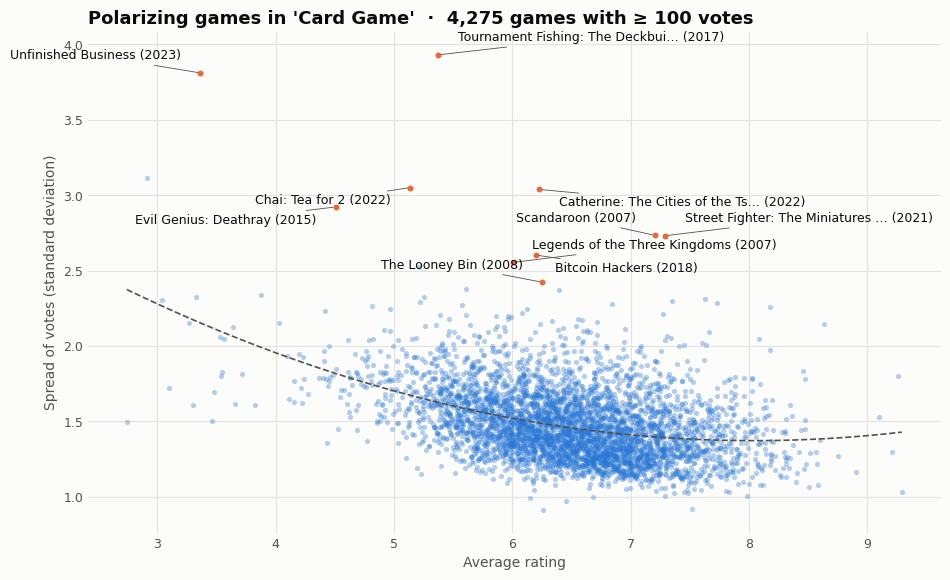

,name,year,avg_rating,stddev_rating,num_votes
0,Tournament Fishing: The Deckbuilding Game,2017,5.37613,3.93138,369.0
1,Unfinished Business,2023,3.36579,3.81122,190.0
2,Catherine: The Cities of the Tsarina,2022,6.22851,3.03847,529.0
3,Chai: Tea for 2,2022,5.14029,3.05102,137.0
4,Street Fighter: The Miniatures Game,2021,7.29130,2.73159,677.0
5,Scandaroon,2007,7.20605,2.73410,194.0
6,Bitcoin Hackers,2018,6.20069,2.60295,101.0
7,Evil Genius: Deathray,2015,4.50960,2.92257,149.0
8,Legends of the Three Kingdoms,2007,6.00387,2.55429,862.0
9,The Looney Bin,2008,6.25246,2.42346,122.0


In [8]:
MIN_VOTES = 100     # the spread is only meaningful with enough votes
N_LABELS = 10        # how many games to label and list

pol = (cat_df[cat_df['num_votes'] >= MIN_VOTES]
       .dropna(subset=['avg_rating', 'stddev_rating']).copy())

# What spread is typical at each rating? (quadratic trend), then measure each game against it
trend = np.polyfit(pol['avg_rating'], pol['stddev_rating'], 2)
pol['expected_std'] = np.polyval(trend, pol['avg_rating'])
pol['extra_spread'] = pol['stddev_rating'] - pol['expected_std']
top = pol.nlargest(N_LABELS, 'extra_spread')

fig, ax = plt.subplots(figsize=(11, 6.5), facecolor=SURFACE)
style_axes(ax)
ax.scatter(pol['avg_rating'], pol['stddev_rating'], s=14, color=BLUE, alpha=0.35, linewidths=0)
xs = np.linspace(pol['avg_rating'].min(), pol['avg_rating'].max(), 100)
ax.plot(xs, np.polyval(trend, xs), color=INK_2, linestyle='--', linewidth=1.2)
ax.scatter(top['avg_rating'], top['stddev_rating'], s=30, color=ORANGE,
           edgecolors=SURFACE, linewidths=1.2, zorder=3)
label_points(ax, top, 'avg_rating', 'stddev_rating')

ax.set_xlabel('Average rating', color=INK_2)
ax.set_ylabel('Spread of votes (standard deviation)', color=INK_2)
ax.set_title(f"Polarizing games in '{CATEGORY}'  ·  {len(pol):,} games with ≥ {MIN_VOTES} votes",
             loc='left', fontsize=13, fontweight='bold', color=INK)
plt.show()

top[['name', 'year', 'avg_rating', 'stddev_rating', 'num_votes']].reset_index(drop=True)

Hover over game to get more information about it?



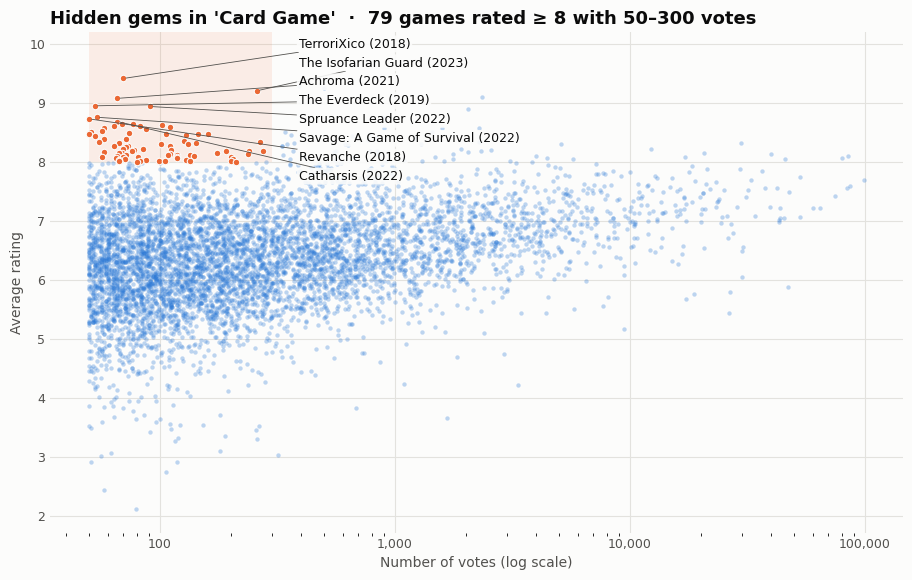

,name,year,avg_rating,num_votes
0,TerroriXico,2018,9.41429,70.0
1,The Isofarian Guard,2023,9.20602,259.0
2,Achroma,2021,9.07727,66.0
3,The Everdeck,2019,8.95094,53.0
4,Spruance Leader,2022,8.93956,91.0
5,Savage: A Game of Survival,2022,8.75720,54.0
6,Revanche,2018,8.73000,50.0
7,Catharsis,2022,8.68485,66.0


In [9]:
MIN_VOTES_GEM = 50      # below this, the average rating is too noisy to trust
MAX_VOTES_GEM = 300     # "few votes" means at most this many
MIN_RATING_GEM = 8    # "highly rated" means at least this
N_LABELS = 8

g = (cat_df.dropna(subset=['avg_rating', 'num_votes'])
     .query('num_votes >= @MIN_VOTES_GEM'))
gems = g[(g['avg_rating'] >= MIN_RATING_GEM) & (g['num_votes'] <= MAX_VOTES_GEM)]
gems = gems.sort_values(['avg_rating', 'num_votes'], ascending=False)

fig, ax = plt.subplots(figsize=(11, 6.5), facecolor=SURFACE)
style_axes(ax)
ax.set_xscale('log')
ax.fill_between([MIN_VOTES_GEM, MAX_VOTES_GEM], MIN_RATING_GEM, 10.2, color=ORANGE, alpha=0.10, linewidth=0)
ax.scatter(g['num_votes'], g['avg_rating'], s=10, color=BLUE, alpha=0.3, linewidths=0)
ax.scatter(gems['num_votes'], gems['avg_rating'], s=22, color=ORANGE, edgecolors=SURFACE,
           linewidths=0.8, zorder=3)
label_column(ax, gems.head(N_LABELS), 'num_votes', 'avg_rating',
             x_text=MAX_VOTES_GEM * 1.3, y_top=10.0, dy=0.32)

ax.set_ylim(top=10.2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel('Number of votes (log scale)', color=INK_2)
ax.set_ylabel('Average rating', color=INK_2)
ax.set_title(f"Hidden gems in '{CATEGORY}'  ·  {len(gems):,} games rated ≥ {MIN_RATING_GEM} "
             f"with {MIN_VOTES_GEM}–{MAX_VOTES_GEM} votes",
             loc='left', fontsize=13, fontweight='bold', color=INK)
plt.show()

gems[['name', 'year', 'avg_rating', 'num_votes']].head(8).reset_index(drop=True)

Hover over game to get more information about it?



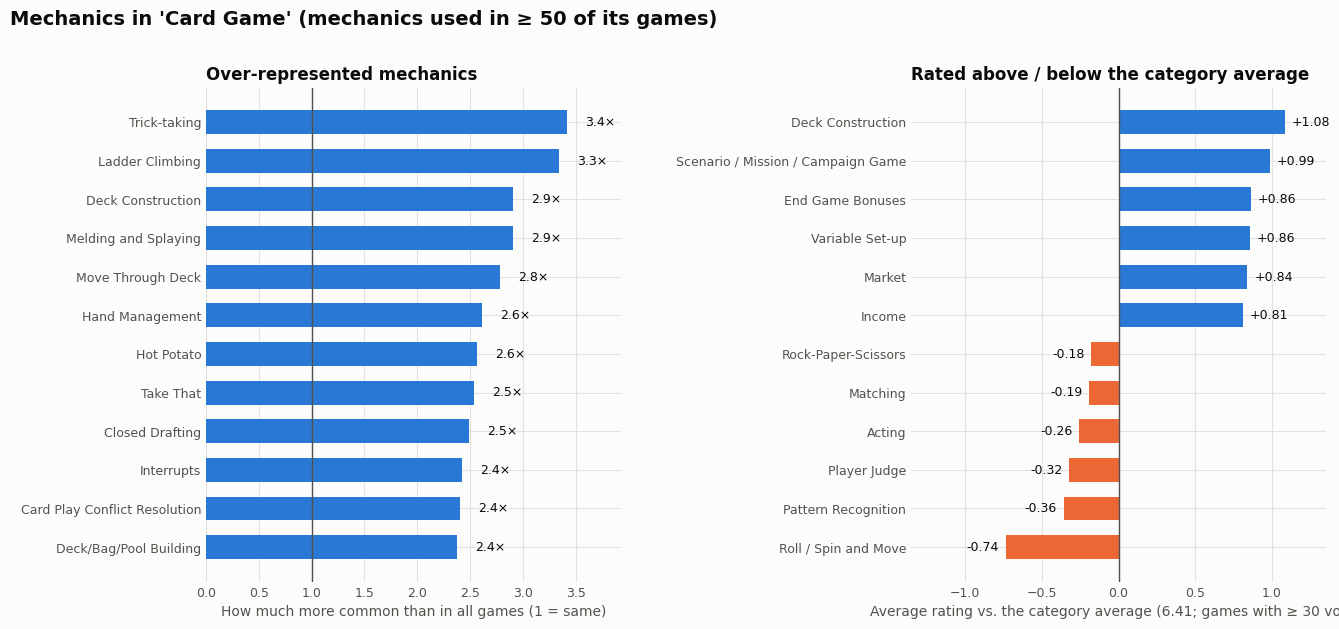

In [10]:
MIN_GAMES_MECH = 50     # ignore mechanics used by fewer games than this in the category
MIN_RATED_MECH = 30     # ... and with fewer rated games than this (for the rating comparison)
MIN_VOTES_RATING = 30   # only games with at least this many votes count toward average ratings
N_SHOW = 12

# A few mechanic names contain commas themselves; protect them before splitting
PROTECT = {
    "Deck, Bag, and Pool Building": "Deck/Bag/Pool Building",
    "I Cut, You Choose": "I Cut/You Choose",
    "Worker Placement, Different Worker Types": "Worker Placement (Different Worker Types)",
}


def split_mechanics(text):
    if not isinstance(text, str):
        return []
    for old, new in PROTECT.items():
        text = text.replace(old, new)
    return sorted({m.strip() for m in text.split(',')} - {'', 'Unknown Mechanics'})


mech = df.assign(mechs=df['mechanic'].apply(split_mechanics))
mech = mech[mech['mechs'].str.len() > 0]                  # games with known mechanics
mech_cat = mech[mech.index.isin(cat_df.index)]

n_all, n_cat = len(mech), len(mech_cat)
count_all = mech.explode('mechs')['mechs'].value_counts()
count_cat = mech_cat.explode('mechs')['mechs'].value_counts()

stats = (count_cat.rename('games').to_frame()
         .join(count_all.rename('games_all'))
         .query('games >= @MIN_GAMES_MECH'))
stats['lift'] = (stats['games'] / n_cat) / (stats['games_all'] / n_all)

# Average rating of the category's games that use each mechanic, vs. the category average
rated_games = mech_cat[mech_cat['num_votes'] >= MIN_VOTES_RATING].dropna(subset=['avg_rating'])
by_mech = rated_games.explode('mechs').groupby('mechs')['avg_rating'].agg(['mean', 'count'])
cat_avg = rated_games['avg_rating'].mean()
stats = stats.join(by_mech)
stats['rating_diff'] = stats['mean'] - cat_avg

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), facecolor=SURFACE)
fig.subplots_adjust(left=0.17, right=0.97, wspace=0.7, top=0.86, bottom=0.10)

# Left: most over-represented
over = stats.nlargest(N_SHOW, 'lift').iloc[::-1]
style_axes(ax1)
ax1.barh(over.index, over['lift'], height=0.62, color=BLUE)
ax1.axvline(1, color=INK_2, linewidth=1)
for y, v in enumerate(over['lift']):
    ax1.text(v + 0.05 * over['lift'].max(), y, f"{v:.1f}×", va='center', fontsize=9, color=INK)
ax1.set_xlim(0, over['lift'].max() * 1.15)
ax1.set_xlabel('How much more common than in all games (1 = same)', color=INK_2)
ax1.set_title('Over-represented mechanics', loc='left', fontsize=12, fontweight='bold', color=INK)

# Right: best and worst rated
r = stats[stats['count'] >= MIN_RATED_MECH].dropna(subset=['rating_diff'])
half = N_SHOW // 2
best_worst = (pd.concat([r.nlargest(half, 'rating_diff'), r.nsmallest(half, 'rating_diff')])
              .sort_values('rating_diff'))
style_axes(ax2)
colors = [BLUE if d >= 0 else ORANGE for d in best_worst['rating_diff']]
ax2.barh(best_worst.index, best_worst['rating_diff'], height=0.62, color=colors)
ax2.axvline(0, color=INK_2, linewidth=1)
pad = 0.04 * best_worst['rating_diff'].abs().max()
for y, v in enumerate(best_worst['rating_diff']):
    ax2.text(v + (pad if v >= 0 else -pad), y, f"{v:+.2f}", va='center',
             ha='left' if v >= 0 else 'right', fontsize=9, color=INK)
lim = best_worst['rating_diff'].abs().max() * 1.25
ax2.set_xlim(-lim, lim)
ax2.set_xlabel(f"Average rating vs. the category average ({cat_avg:.2f}; games with ≥ {MIN_VOTES_RATING} votes)",
               color=INK_2)
ax2.set_title('Rated above / below the category average',
              loc='left', fontsize=12, fontweight='bold', color=INK)

fig.suptitle(f"Mechanics in '{CATEGORY}' (mechanics used in ≥ {MIN_GAMES_MECH} of its games)",
             x=0.03, ha='left', fontsize=14, fontweight='bold', color=INK)
plt.show()

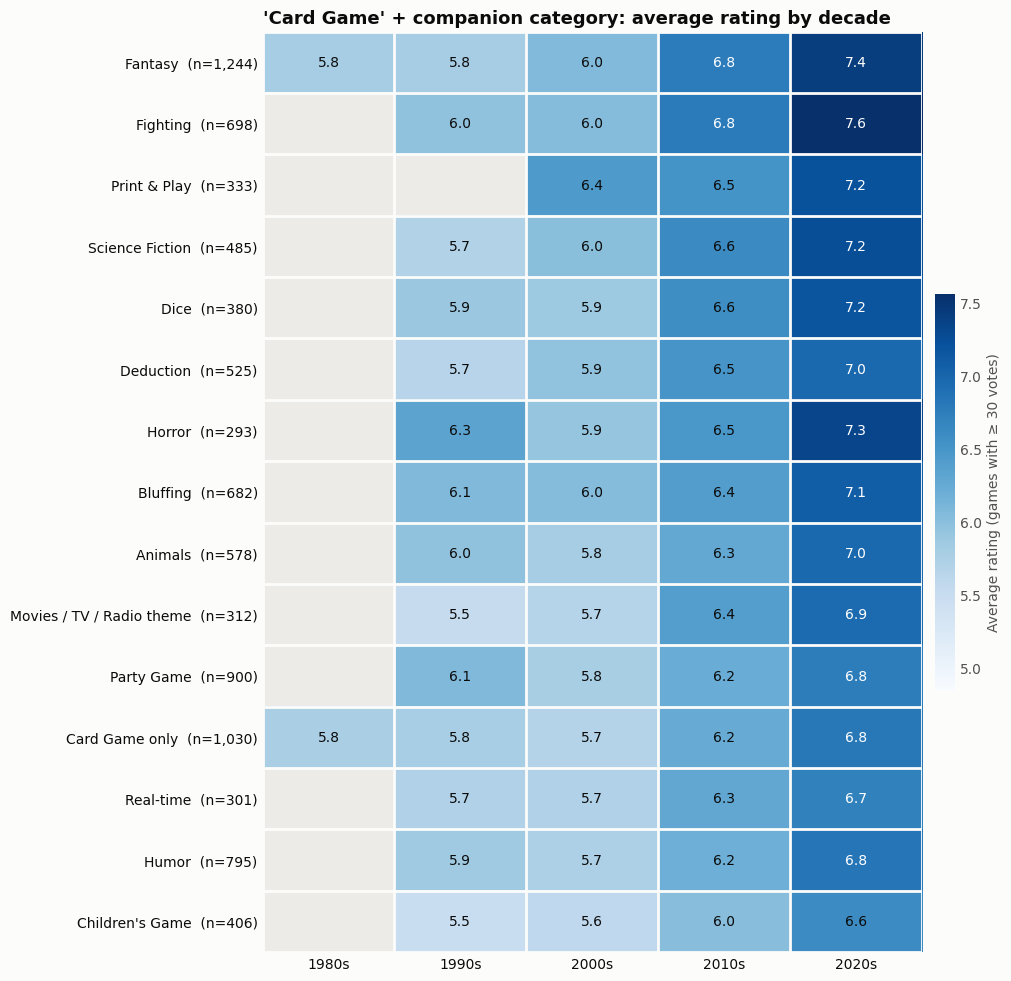

In [11]:
DECADE_MIN = 1980       # earlier decades have too few games
TOP_K = 15              # number of companion categories to show (most common first)
MIN_CELL = 10           # blank out decade/category cells with fewer rated games than this
MIN_VOTES = 30          # only games with at least this many votes count (few-vote averages are noisy)

c = cat_df[cat_df['num_votes'] >= MIN_VOTES].dropna(subset=['avg_rating']).copy()
c = c[c['year'] >= DECADE_MIN]
c['decade'] = (c['year'] // 10 * 10).astype(int)

# Companion categories = every other category on the game; games with none get their own row
c['companions'] = c['category'].str.split(', ').apply(
    lambda cats: [x for x in cats if x != CATEGORY] or [f'{CATEGORY} only'])
long = c.explode('companions')

top_comp = long['companions'].value_counts().head(TOP_K)
sub = long[long['companions'].isin(top_comp.index)]
heat = sub.pivot_table(index='companions', columns='decade', values='avg_rating', aggfunc='mean')
n = sub.pivot_table(index='companions', columns='decade', values='avg_rating', aggfunc='count')
heat = heat.where(n >= MIN_CELL)

# Order rows by overall average rating, best at the top
order = sub.groupby('companions')['avg_rating'].mean().sort_values(ascending=False).index
heat = heat.loc[order]

fig, ax = plt.subplots(figsize=(10, 0.5 * len(heat) + 2.2), facecolor=SURFACE, layout='constrained')
cmap = plt.get_cmap('Blues').copy()
cmap.set_bad(color='#ecebe7')                               # blank cells
vmin, vmax = np.nanmin(heat.values), np.nanmax(heat.values)
im = ax.imshow(np.ma.masked_invalid(heat.values), cmap=cmap, aspect='auto',
               vmin=vmin - 0.3 * (vmax - vmin), vmax=vmax)
ax.set_xticks(range(len(heat.columns)), [f"{d}s" for d in heat.columns])
ax.set_yticks(range(len(heat)), [f"{name}  (n={top_comp[name]:,})" for name in heat.index])
ax.tick_params(length=0, labelsize=10, labelcolor=INK)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-.5, len(heat.columns)), minor=True)
ax.set_yticks(np.arange(-.5, len(heat)), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=2)
ax.tick_params(which='minor', length=0)

mid = vmin + 0.55 * (vmax - vmin)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha='center', va='center', fontsize=10,
                    color='white' if v > mid else INK)

cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label(f'Average rating (games with ≥ {MIN_VOTES} votes)', color=INK_2)
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0, labelcolor=INK_2)
ax.set_title(f"'{CATEGORY}' + companion category: average rating by decade",
             loc='left', fontsize=13, fontweight='bold', color=INK)
plt.show()

In [12]:

#!pip install -q umap-learn


In [13]:
import umap
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import StandardScaler, normalize

# ---- settings ----------------------------------------------------------------
MIN_VOTES_MAP = 100       # only games with at least this many votes
MAX_GAMES = 3000          # keep the most-voted games (more is possible, but the plot gets crowded)
N_CLUSTERS = 8            # number of groups
MIN_FEATURE_GAMES = 10    # ignore mechanics/categories used by fewer games than this
W_MECH, W_CAT, W_NUM = 1, 1, 0.5   # how much each block of features counts
UMAP_NEIGHBORS = 30       # smaller = more local detail, larger = more of the overall layout
UMAP_MIN_DIST = 0.1       # smaller = tighter islands
NUMERIC = ['complexity', 'avg_rating']
#NUMERIC = ['complexity', 'max_time', 'min_players', 'max_players']
# -------------------------------------------------------------------------------

games = cat_df[cat_df['num_votes'] >= MIN_VOTES_MAP].copy()
games['mechs'] = games['mechanic'].apply(split_mechanics)
games = games[games['mechs'].str.len() > 0]
games = games.nlargest(MAX_GAMES, 'num_votes').reset_index(drop=True)
games['cats'] = games['category'].fillna('').str.split(', ').apply(
    lambda cats: [c for c in cats if c and c != CATEGORY])


def indicator_block(token_lists):
    """Yes/no matrix (games x features), plus a TF-IDF weighted copy and the feature names."""
    cv = CountVectorizer(analyzer=lambda tokens: tokens, binary=True, min_df=MIN_FEATURE_GAMES)
    counts = cv.fit_transform(token_lists)
    return TfidfTransformer().fit_transform(counts), counts, cv.get_feature_names_out()


Xm, Cm, names_m = indicator_block(games['mechs'])
Xc, Cc, names_c = indicator_block(games['cats'])

# Numeric block: playtime on a log scale, missing values filled with the median
use = [c for c in NUMERIC if games[c].notna().mean() >= 0.5]
num = games[use].copy()
if 'max_time' in num:
    num['max_time'] = np.log1p(num['max_time'])
num = num.fillna(num.median())
Xn = StandardScaler().fit_transform(num) * W_NUM / np.sqrt(len(use))

X = sparse.hstack([W_MECH * Xm, W_CAT * Xc, sparse.csr_matrix(Xn)]).tocsr()
Z = normalize(TruncatedSVD(n_components=min(30, X.shape[1] - 1), random_state=0).fit_transform(X))

labels = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=0).fit_predict(Z)
xy = umap.UMAP(n_neighbors=UMAP_NEIGHBORS, min_dist=UMAP_MIN_DIST, metric='cosine',
               random_state=0).fit_transform(Z)

# Number the clusters by size (1 = biggest) and name each by what is unusually common in it
order = pd.Series(labels).value_counts().index.tolist()
games['cluster'] = [order.index(k) + 1 for k in labels]
games['x'], games['y'] = xy[:, 0], xy[:, 1]

F = sparse.hstack([Cm, Cc]).tocsr()
feature_names = np.concatenate([names_m, names_c])
overall = np.asarray(F.mean(axis=0)).ravel()
cluster_names, rows = {}, []
for k in range(1, N_CLUSTERS + 1):
    mask = (games['cluster'] == k).values
    lift = np.asarray(F[mask].mean(axis=0)).ravel() - overall   # more common here than overall
    top = [feature_names[i] for i in np.argsort(lift)[::-1][:3] if lift[i] > 0.05]
    cluster_names[k] = ', '.join(top) if top else '(mixed)'
    members = games[mask]
    rows.append({'cluster': k, 'games': mask.sum(), 'typical for this group': cluster_names[k],
                 'median complexity': members['complexity'].median(),
                 'median max time (min)': members['max_time'].median(),
                 'avg rating': members['avg_rating'].mean()})

print(f"{len(games):,} games, {F.shape[1]} mechanics/categories used as features")
pd.DataFrame(rows).round(2).set_index('cluster')

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


3,000 games, 157 mechanics/categories used as features


,games,typical for this group,median complexity,median max time (min),avg rating
cluster,,,,,
1,690,"Deck/Bag/Pool Building, Open Drafting, Science...",2.42,60.0,7.15
2,690,"Children's Game, Humor, Pattern Recognition",1.32,30.0,5.92
3,414,"Set Collection, Open Drafting",1.57,30.0,6.42
4,376,"Fantasy, Variable Player Powers, Fighting",2.18,45.0,7.07
5,291,"Bluffing, Deduction, Party Game",1.42,30.0,6.63
6,226,"Take That, Humor, Hand Management",1.50,30.0,6.29
7,174,"Cooperative Game, Puzzle, Storytelling",1.63,45.0,6.73
8,139,"Trick-taking, Team-Based Game, Predictive Bid",1.77,40.0,6.62


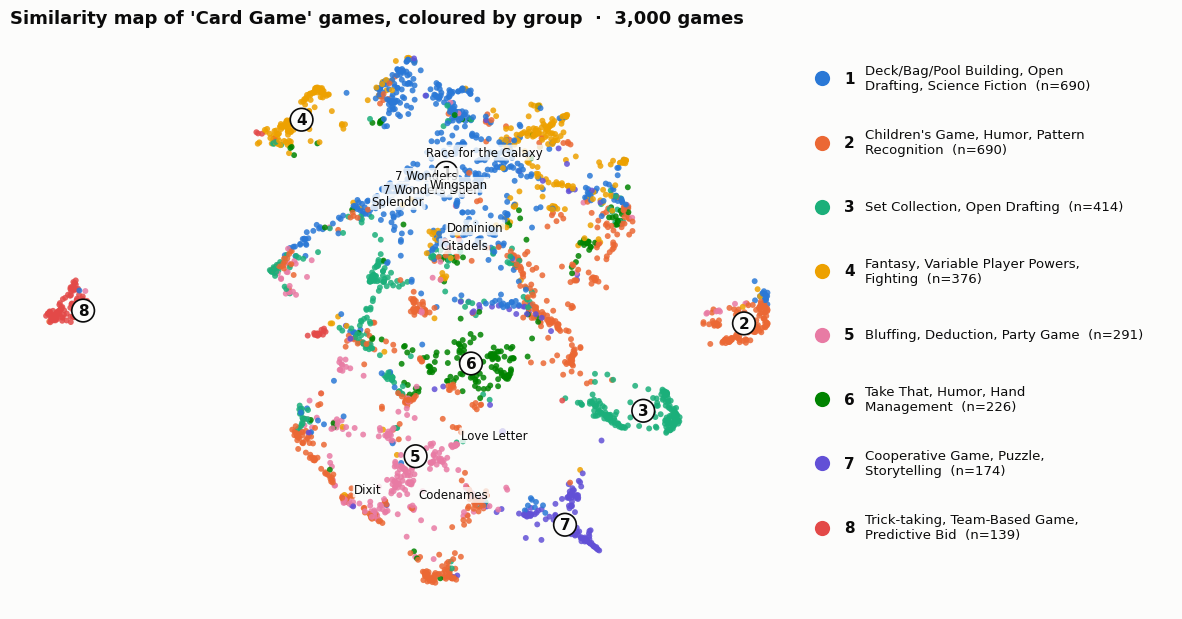

In [14]:
import textwrap
N_LABEL_GAMES = 10      # label this many of the most-voted games for orientation

# Colours in a fixed order, biggest cluster first. Beyond 8 clusters the rest turn grey.
CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
OTHER_GREY = '#b9b8b2'


def cluster_color(k):
    return CLUSTER_COLORS[k - 1] if k <= len(CLUSTER_COLORS) else OTHER_GREY


fig, (ax, ax_txt) = plt.subplots(1, 2, figsize=(15, 7.5), facecolor=SURFACE,
                                 gridspec_kw={'width_ratios': [3, 1.35], 'wspace': 0.02})
style_axes(ax)
ax.grid(False)
ax.set_xticks([]); ax.set_yticks([])

ax.scatter(games['x'], games['y'], s=18, c=[cluster_color(k) for k in games['cluster']],
           linewidths=0, alpha=0.85)

# Numbered marker per cluster (in the densest part of its points), so colour is never the only clue
span = max(np.ptp(games['x']), np.ptp(games['y']))
for k in range(1, N_CLUSTERS + 1):
    pts = games.loc[games['cluster'] == k, ['x', 'y']].values
    dist = np.hypot(pts[:, None, 0] - pts[None, :, 0], pts[:, None, 1] - pts[None, :, 1])
    cx, cy = pts[(dist < 0.06 * span).sum(axis=1).argmax()]
    ax.text(cx, cy, str(k), ha='center', va='center', fontsize=11, fontweight='bold', color=INK,
            bbox=dict(boxstyle='circle,pad=0.25', fc=SURFACE, ec=INK, lw=1.2))

# Name a few well-known games
for _, r in games.nlargest(N_LABEL_GAMES, 'num_votes').iterrows():
    ax.annotate(short(r['name'], 24), (r['x'], r['y']), xytext=(6, 6), textcoords='offset points',
                fontsize=8.5, color=INK,
                bbox=dict(boxstyle='round,pad=0.12', fc=SURFACE, ec='none', alpha=0.8))

ax.set_title(f"Similarity map of '{CATEGORY}' games, coloured by group  ·  {len(games):,} games",
             loc='left', fontsize=13, fontweight='bold', color=INK)

# Key: colour, number, what the group is typical for
ax_txt.axis('off')
ax_txt.set_xlim(0, 1)
ax_txt.set_ylim(0, 1)
step = 1 / (N_CLUSTERS + 1)
for k in range(1, N_CLUSTERS + 1):
    y = 1 - k * step + 0.03
    n_k = (games['cluster'] == k).sum()
    ax_txt.scatter([0.02], [y], s=120, color=cluster_color(k), linewidths=0, clip_on=False)
    ax_txt.text(0.08, y, f"{k}", fontsize=11, fontweight='bold', color=INK, va='center')
    ax_txt.text(0.14, y, textwrap.fill(cluster_names[k], 32) + f"  (n={n_k})",
                fontsize=9.5, color=INK, va='center')
plt.show()

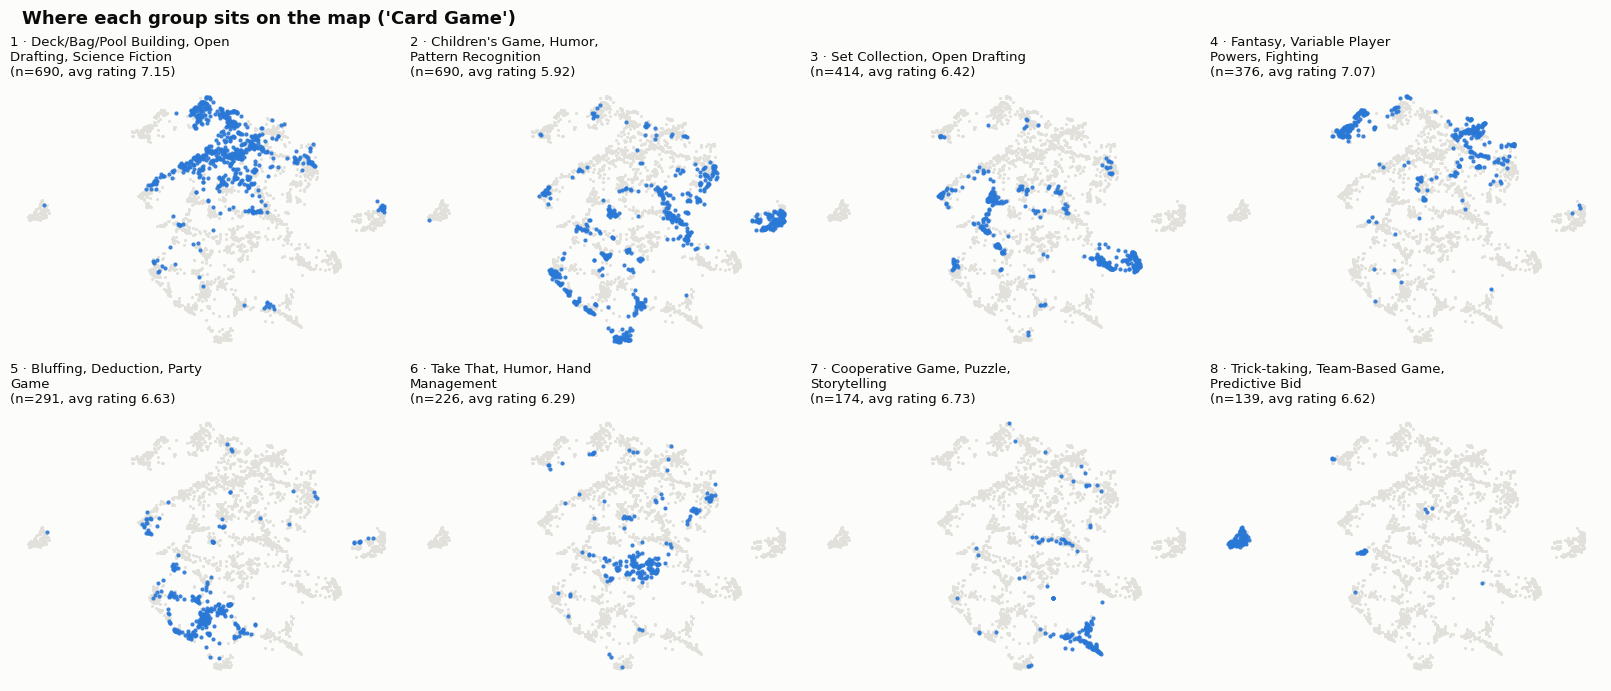

In [15]:
ncols = 4
nrows = int(np.ceil(N_CLUSTERS / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows), facecolor=SURFACE,
                         layout='constrained')
for ax, k in zip(axes.ravel(), range(1, N_CLUSTERS + 1)):
    members = games[games['cluster'] == k]
    ax.set_facecolor(SURFACE)
    ax.scatter(games['x'], games['y'], s=5, color='#e1e0db', linewidths=0)
    ax.scatter(members['x'], members['y'], s=9, color=BLUE, linewidths=0, alpha=0.9)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(f"{k} · " + textwrap.fill(cluster_names[k], 30) + f"\n(n={len(members)}, "
                 f"avg rating {members['avg_rating'].mean():.2f})",
                 loc='left', fontsize=9.5, color=INK)
for ax in axes.ravel()[N_CLUSTERS:]:
    ax.axis('off')
fig.suptitle(f"Where each group sits on the map ('{CATEGORY}')", x=0.01, ha='left',
             fontsize=13, fontweight='bold', color=INK)
plt.show()

In [16]:
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import StandardScaler, normalize

# ---- settings (this cell runs once; the weights are set with sliders in the next cell) ----
MIN_VOTES_MAP = 100       # only games with at least this many votes
MAX_GAMES = 3000          # keep the most-voted games (more is possible, but the plot gets crowded)
MIN_FEATURE_GAMES = 10    # ignore mechanics/categories used by fewer games than this
NUMERIC_ON = ['complexity', 'max_time', 'min_players', 'max_players']   # their weight slider starts at 0.5
NUMERIC_OFF = ['min_time', 'min_age']                                    # slider is there, but starts at 0
# -------------------------------------------------------------------------------------------

games = cat_df[cat_df['num_votes'] >= MIN_VOTES_MAP].copy()
games['mechs'] = games['mechanic'].apply(split_mechanics)
games = games[games['mechs'].str.len() > 0]
games = games.nlargest(MAX_GAMES, 'num_votes').reset_index(drop=True)
games['cats'] = games['category'].fillna('').str.split(', ').apply(
    lambda cats: [c for c in cats if c and c != CATEGORY])


def indicator_block(token_lists):
    """Yes/no matrix (games x features), plus a TF-IDF weighted copy and the feature names."""
    cv = CountVectorizer(analyzer=lambda tokens: tokens, binary=True, min_df=MIN_FEATURE_GAMES)
    counts = cv.fit_transform(token_lists)
    return TfidfTransformer().fit_transform(counts), counts, cv.get_feature_names_out()


Xm, Cm, names_m = indicator_block(games['mechs'])
Xc, Cc, names_c = indicator_block(games['cats'])

# Numeric features: playtime on a log scale, missing values filled with the median, every column
# standardised. (Each column gets its own slider weight in the next cell.)
use = [c for c in NUMERIC_ON + NUMERIC_OFF if games[c].notna().mean() >= 0.5]
num = games[use].copy()
for time_col in ('min_time', 'max_time'):
    if time_col in num:
        num[time_col] = np.log1p(num[time_col])
num = num.fillna(num.median())
Xn = StandardScaler().fit_transform(num)

# What each group is "typical for" is worked out from mechanics + categories
F = sparse.hstack([Cm, Cc]).tocsr()
feature_names = np.concatenate([names_m, names_c])
overall = np.asarray(F.mean(axis=0)).ravel()

N_CLUSTERS = 8            # set by a slider in the next cell
cluster_names = {}        # filled in by the next cell

print(f"{len(games):,} games, {F.shape[1]} mechanics/categories, numeric features used: {use}")

3,000 games, 157 mechanics/categories, numeric features used: ['complexity', 'max_time', 'min_players', 'max_players', 'min_time', 'min_age']


In [17]:
import io
import umap
import ipywidgets as widgets
from ipywidgets import Layout
from IPython.display import display
from matplotlib.figure import Figure

# ---- settings ----------------------------------------------------------------
UMAP_NEIGHBORS = 30       # smaller = more local detail, larger = more of the overall layout
UMAP_MIN_DIST = 0.1       # smaller = tighter islands
REPRODUCIBLE = True       # True: same map every run (UMAP on one core). False: faster, uses all cores,
                          # and the map varies slightly between runs
N_LABEL_GAMES = 10        # label this many of the most-voted games for orientation
# -------------------------------------------------------------------------------

# Colours in a fixed order, biggest group first (numbers on the map back them up)
CLUSTER_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
state = {'weights': None, 'Z': None, 'xy': None}


def build_layout(w_mech, w_cat, w_nums):
    """Weighted features -> 30 dimensions -> 2D layout (the slow part)."""
    n = len(games)
    Xnum = sparse.csr_matrix(Xn * (0.5 * np.array(w_nums)))      # one weight per numeric column
    X = sparse.hstack([w_mech * Xm, w_cat * Xc, Xnum,
                       sparse.csr_matrix(np.full((n, 1), 1e-3))]).tocsr()   # tiny constant: no all-zero rows
    Z = normalize(TruncatedSVD(n_components=min(30, X.shape[1] - 1), random_state=0).fit_transform(X))
    # Start from the previous layout so the map moves gently instead of reshuffling completely
    start = state['xy'] if state['xy'] is not None else 'spectral'
    speed = dict(random_state=0) if REPRODUCIBLE else dict(n_jobs=-1)
    xy = umap.UMAP(n_neighbors=UMAP_NEIGHBORS, min_dist=UMAP_MIN_DIST, metric='cosine',
                   init=start, **speed).fit_transform(Z)
    return Z, xy


def assign_clusters(Z, k):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    order = pd.Series(labels).value_counts().index.tolist()      # number the groups by size
    return np.array([order.index(l) + 1 for l in labels])


def name_clusters(cluster, k):
    names = {}
    for c in range(1, k + 1):
        diff = np.asarray(F[cluster == c].mean(axis=0)).ravel() - overall   # more common here than overall
        top = [feature_names[i] for i in np.argsort(diff)[::-1][:3] if diff[i] > 0.05]
        names[c] = ', '.join(top) if top else '(mixed)'
    return names


def render(color_by):
    """Draw the map and return it as PNG bytes."""
    k = N_CLUSTERS
    fig = Figure(figsize=(15, 7.5), facecolor=SURFACE)
    ax, ax_txt = fig.subplots(1, 2, gridspec_kw={'width_ratios': [3, 1.35], 'wspace': 0.02})
    style_axes(ax)
    ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])

    if color_by == 'Group':
        ax.scatter(games['x'], games['y'], s=18, c=[CLUSTER_COLORS[c - 1] for c in games['cluster']],
                   linewidths=0, alpha=0.85)
    else:
        rated = games.dropna(subset=['avg_rating']).sort_values('avg_rating')
        ax.scatter(games['x'], games['y'], s=14, color='#e1e0db', linewidths=0)     # no rating
        sc = ax.scatter(rated['x'], rated['y'], s=16, c=rated['avg_rating'], cmap='Blues',
                        vmin=4.5, vmax=8.5, linewidths=0, alpha=0.9)
        cbar = fig.colorbar(sc, ax=ax, location='bottom', fraction=0.04, pad=0.02, shrink=0.45)
        cbar.set_label('Average rating', color=INK_2)
        cbar.outline.set_visible(False)
        cbar.ax.tick_params(length=0, labelcolor=INK_2)

    # One numbered marker per group, in the densest part of its points
    span = max(np.ptp(games['x']), np.ptp(games['y']))
    for c in range(1, k + 1):
        pts = games.loc[games['cluster'] == c, ['x', 'y']].values
        dist = np.hypot(pts[:, None, 0] - pts[None, :, 0], pts[:, None, 1] - pts[None, :, 1])
        cx, cy = pts[(dist < 0.06 * span).sum(axis=1).argmax()]
        ax.text(cx, cy, str(c), ha='center', va='center', fontsize=11, fontweight='bold', color=INK,
                bbox=dict(boxstyle='circle,pad=0.25', fc=SURFACE, ec=INK, lw=1.2))

    for _, r in games.nlargest(N_LABEL_GAMES, 'num_votes').iterrows():
        ax.annotate(short(r['name'], 24), (r['x'], r['y']), xytext=(6, 6), textcoords='offset points',
                    fontsize=8.5, color=INK,
                    bbox=dict(boxstyle='round,pad=0.12', fc=SURFACE, ec='none', alpha=0.8))
    what = 'coloured by group' if color_by == 'Group' else 'coloured by average rating'
    ax.set_title(f"Similarity map of '{CATEGORY}' games, {what}  ·  {len(games):,} games",
                 loc='left', fontsize=13, fontweight='bold', color=INK)

    # Key: number (and colour) + what the group is typical for
    ax_txt.axis('off')
    ax_txt.set_xlim(0, 1); ax_txt.set_ylim(0, 1)
    step = 1 / (k + 1)
    for c in range(1, k + 1):
        y = 1 - c * step + 0.03
        n_c = (games['cluster'] == c).sum()
        if color_by == 'Group':
            ax_txt.scatter([0.02], [y], s=120, color=CLUSTER_COLORS[c - 1], linewidths=0, clip_on=False)
        ax_txt.text(0.08, y, f"{c}", fontsize=11, fontweight='bold', color=INK, va='center')
        ax_txt.text(0.14, y, textwrap.fill(cluster_names[c], 32) + f"  (n={n_c})",
                    fontsize=9.5, color=INK, va='center')
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=100, facecolor=SURFACE)
    return buf.getvalue()


def update(change=None):
    global N_CLUSTERS
    weights = (w_mech.value, w_cat.value) + tuple(s.value for s in num_sliders.values())
    if sum(weights) == 0:
        status.value = 'Set at least one weight above 0.'
        return
    status.value = 'Updating… (a changed weight re-runs UMAP, which takes a few seconds)'
    try:
        if state['weights'] != weights:                  # only the weights need a new layout
            Z, xy = build_layout(weights[0], weights[1], weights[2:])
            state.update(weights=weights, Z=Z, xy=xy)
        N_CLUSTERS = k_slider.value
        games['cluster'] = assign_clusters(state['Z'], N_CLUSTERS)
        games['x'], games['y'] = state['xy'][:, 0], state['xy'][:, 1]
        cluster_names.clear()
        cluster_names.update(name_clusters(games['cluster'].values, N_CLUSTERS))
        chart.value = render(color_by.value)
        status.value = ''
    except Exception as e:
        status.value = f'Error: {e}'
        raise


def slider(cls, label, **kw):
    return cls(description=label, continuous_update=False, style={'description_width': '130px'},
               layout=Layout(width='430px'), **kw)


w_mech = slider(widgets.FloatSlider, 'Mechanics weight', value=1.0, min=0, max=2, step=0.1)
w_cat = slider(widgets.FloatSlider, 'Categories weight', value=1.0, min=0, max=2, step=0.1)
NUM_LABELS = {'complexity': 'Complexity', 'max_time': 'Playtime (max)', 'min_time': 'Playtime (min)',
              'min_players': 'Min. players', 'max_players': 'Max. players', 'min_age': 'Min. age'}
num_sliders = {col: slider(widgets.FloatSlider, NUM_LABELS.get(col, col), min=0, max=2, step=0.1,
                           value=0.5 if col in NUMERIC_ON else 0.0)
               for col in use}
k_slider = slider(widgets.IntSlider, 'Number of groups', value=8, min=2, max=8, step=1)
color_by = widgets.Dropdown(options=['Group', 'Average rating'], value='Group', description='Colour by',
                            style={'description_width': '130px'}, layout=Layout(width='430px'))
status = widgets.Label(value='')
chart = widgets.Image(format='png', layout=Layout(width='100%', max_width='1500px'))

for control in [w_mech, w_cat, k_slider, color_by] + list(num_sliders.values()):
    control.observe(update, names='value')

num_rows = [widgets.HBox(list(num_sliders.values())[i:i + 2]) for i in range(0, len(num_sliders), 2)]
display(widgets.VBox([
    widgets.HBox([w_mech, w_cat]),
    widgets.Label('Numeric features (0 = ignore)'),
    *num_rows,
    widgets.HBox([k_slider, color_by]),
    status,
    chart]))
update()      # draw the first map

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr